# 9-loyiha
Qoidaga asoslangan yordamchi tizim va qaror daraxti

cdss_patients.csv: sun’iy holatlar. Qoidalar qo‘llanmadagi o‘quv misolini bajaradi, klinik protokol yoki tavsiya emas.


In [1]:
# Qoidaga asoslangan yordamchi tizim va qaror daraxti
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

ROOT = (Path(__file__).resolve().parent
        if "__file__" in globals() else Path.cwd())
DATA, OUT = ROOT / "data", ROOT / "outputs"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 42

def save_json(name, value):
    text = json.dumps(value, indent=2, ensure_ascii=False,
                      allow_nan=False, default=str)
    (OUT / name).write_text(text, encoding="utf-8")

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140)
    plt.close()

from sklearn.metrics import (accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix,
    brier_score_loss, ConfusionMatrixDisplay)

def binary_metrics(y, probability, threshold=0.5):
    pred = np.asarray(probability) >= threshold
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(n=int(len(y)), threshold=float(threshold),
        accuracy=float(accuracy_score(y, pred)),
        precision=float(precision_score(y, pred, zero_division=0)),
        recall=float(recall_score(y, pred, zero_division=0)),
        specificity=float(tn / (tn + fp)) if tn + fp else None,
        f1=float(f1_score(y, pred, zero_division=0)),
        roc_auc=float(roc_auc_score(y, probability))
            if len(np.unique(y)) == 2 else None,
        brier=float(brier_score_loss(y, probability)),
        tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
import joblib

def demo_rule(row):
    fields = ["age", "spo2", "temperature", "heart_rate", "comorbidity"]
    if row[fields].isna().any() or not 0 <= row.spo2 <= 100:
        return "needs_review"
    if row.spo2 < 90 or row.confusion:
        return "demo_red"
    if row.spo2 < 94 or row.temperature >= 39:
        return "demo_amber"
    return "demo_green"

def main():
    path = DATA / "cdss_patients.csv"
    if not path.exists():
        rng = np.random.default_rng(SEED)
        n = 500
        df = pd.DataFrame({"patient_id": np.arange(n),
            "age": rng.integers(18, 90, n),
            "temperature": rng.normal(37.4, 1, n),
            "heart_rate": rng.normal(85, 20, n),
            "spo2": rng.uniform(86, 100, n),
            "comorbidity": rng.integers(0, 4, n),
            "confusion": rng.random(n) < .05})
        score = 2 * (df.age >= 65) + 3 * (df.spo2 < 94)
        score += (df.heart_rate > 110) + df.comorbidity.clip(upper=2)
        p = 1 / (1 + np.exp(-(score - 4)))
        df["outcome"] = rng.binomial(1, p)
        df.to_csv(path, index=False)
    df = pd.read_csv(path)
    df["demo_priority"] = df.apply(demo_rule, axis=1)
    df["risk_score"] = (2 * (df.age >= 65) + 3 * (df.spo2 < 94)
        + (df.heart_rate > 110) + df.comorbidity.clip(upper=2))
    df.to_csv(OUT / "rules_and_scores.csv", index=False)
    features = ["age", "temperature", "heart_rate", "spo2", "comorbidity"]
    valid = df[features + ["outcome"]].notna().all(axis=1)
    usable = df[valid]
    train, test = train_test_split(usable.index, test_size=.2,
        random_state=SEED, stratify=usable.outcome)
    tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=15,
                                  random_state=SEED)
    tree.fit(df.loc[train, features], df.loc[train, "outcome"])
    p = tree.predict_proba(df.loc[test, features])[:, 1]
    result = binary_metrics(df.loc[test, "outcome"], p)
    save_json("metrics.json", {"source": "synthetic", "test": result})
    (OUT / "decision_tree.txt").write_text(
        export_text(tree, feature_names=features), encoding="utf-8")
    joblib.dump(tree, OUT / "decision_tree.joblib")
    df.demo_priority.value_counts().plot.bar(
        ylabel="Sun’iy holatlar", title="Faqat o‘quv qoidalari")
    save_plot("demo_priorities.png")
    save_json("split.json", {"train": train.tolist(),
                             "test": test.tolist()})
    print(json.dumps(result, indent=2))

if __name__ == "__main__":
    main()


{
  "n": 100,
  "threshold": 0.5,
  "accuracy": 0.76,
  "precision": 0.7037037037037037,
  "recall": 0.8260869565217391,
  "specificity": 0.7037037037037037,
  "f1": 0.76,
  "roc_auc": 0.8397745571658615,
  "brier": 0.1626511527732534,
  "tn": 38,
  "fp": 16,
  "fn": 8,
  "tp": 38
}


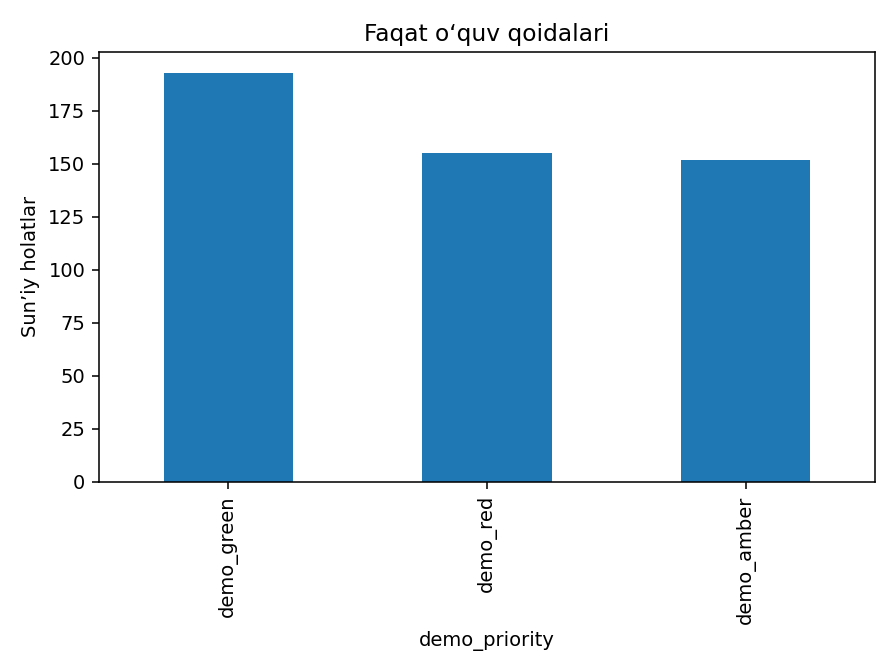

In [2]:
from IPython.display import display, Image
for path in sorted(OUT.glob("*.png")):
    display(Image(filename=str(path)))
